In [1]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px


In [2]:
from src.data_loader import load_csvs_from_gcs
from src.preprocessing import preprocess_house_data


GCS URI: gs://riva_ml_datasets/house_rent/*.csv
Files loaded: 3
Combined rows: 13910
                     house_type  house_size           location   city  \
0        1 RK Studio Apartment          400            kalkaji  delhi   
1        1 RK Studio Apartment          400  mansarover garden  delhi   
2      2 BHK Independent Floor          500        uttam nagar  delhi   
3      3 BHK Independent House         1020         model town  delhi   
4              2 BHK Apartment          810   sector 13 rohini  delhi   
...                         ...         ...                ...    ...   
13905          1 BHK Apartment          655              wakad   pune   
13906          2 BHK Apartment          920    pimple saudagar   pune   
13907          1 BHK Apartment          650    pimple saudagar   pune   
13908          2 BHK Apartment         1200    pimple saudagar   pune   
13909          2 BHK Apartment          933           rahatani   pune   

        latitude  longitude  price  nu

In [3]:
df = load_csvs_from_gcs("gs://riva_ml_datasets/house_rent/*.csv", "ai-ml-projects-260916")
df = preprocess_house_data(df)

GCS URI: gs://riva_ml_datasets/house_rent/*.csv
Files loaded: 3
Combined rows: 13910


In [4]:
df.isnull().sum()

house_type               0
house_size               0
location                 0
city                     0
latitude                 0
longitude                0
price                    0
num_bathrooms            0
num_balconies            0
is_negotiable            0
price_sqft           13902
verification_date        0
description            831
security_deposite    13902
Status                   0
source_file              0
bhk                      0
property_type          542
verification_days     4140
dtype: int64

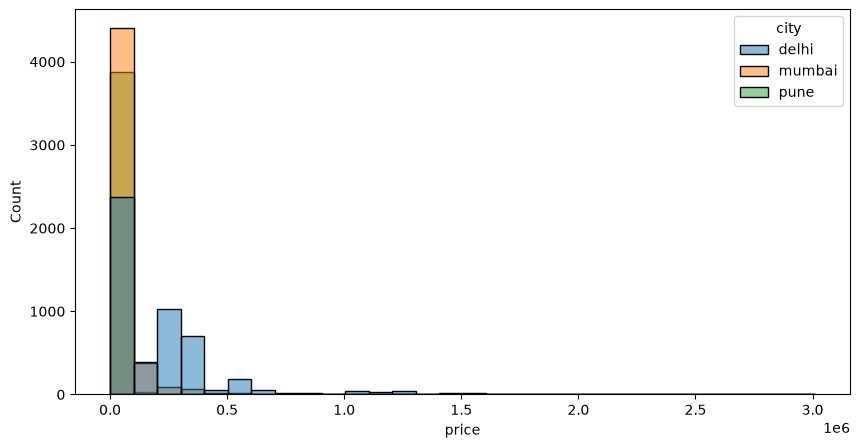

In [5]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="price", hue="city", bins=30,)
plt.show()

In [6]:
df['city'].value_counts()

city
delhi     5000
mumbai    4992
pune      3910
Name: count, dtype: int64

<Axes: xlabel='city'>

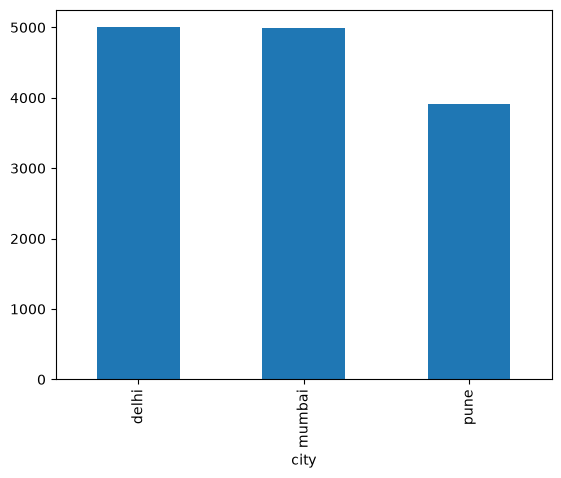

In [7]:
df['city'].value_counts().plot(kind="bar")

In [8]:
df['price'].mean()

np.float64(108526.76176089772)

In [9]:
num_cols = df.select_dtypes(exclude="object").columns

In [10]:
num_cols

Index(['house_size', 'latitude', 'longitude', 'price', 'num_bathrooms',
       'num_balconies', 'is_negotiable', 'price_sqft', 'security_deposite',
       'bhk', 'verification_days'],
      dtype='str')

In [11]:
cat_cols = df.select_dtypes(exclude=[int, float]).columns

In [12]:
cat_cols

Index(['house_type', 'location', 'city', 'verification_date', 'description',
       'Status', 'source_file', 'property_type'],
      dtype='str')

In [13]:
df['house_size']

0         400
1         400
2         500
3        1020
4         810
         ... 
13905     655
13906     920
13907     650
13908    1200
13909     933
Name: house_size, Length: 13902, dtype: int64

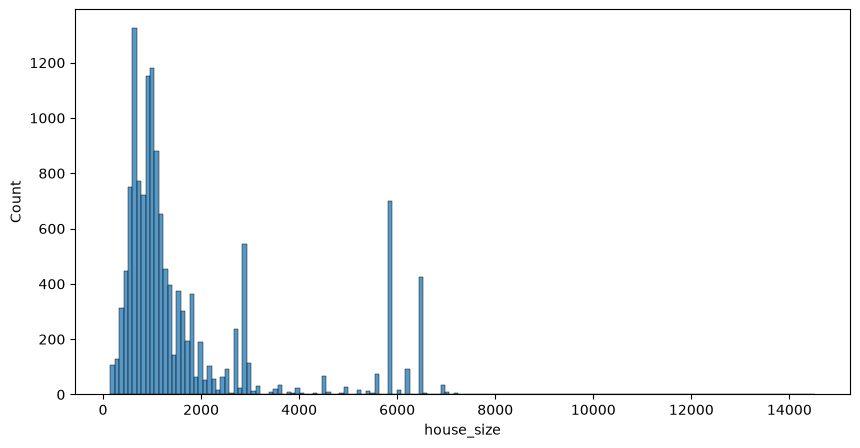

In [14]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="house_size")
plt.show()

#### Looking at the above plot, we can say, more than 1000 properties in the dataset, have the house size of 500 to 2000 sqft
#### There are a few properties with house sizes less than 500 sqft and more than 2000 sqft, but they are significantly fewer in number compared to the properties within the 500 to 2000 sqft range. This indicates that the majority of the properties in the dataset fall within this size range, which could be a common preference among buyers or a reflection of the available housing stock in the area.

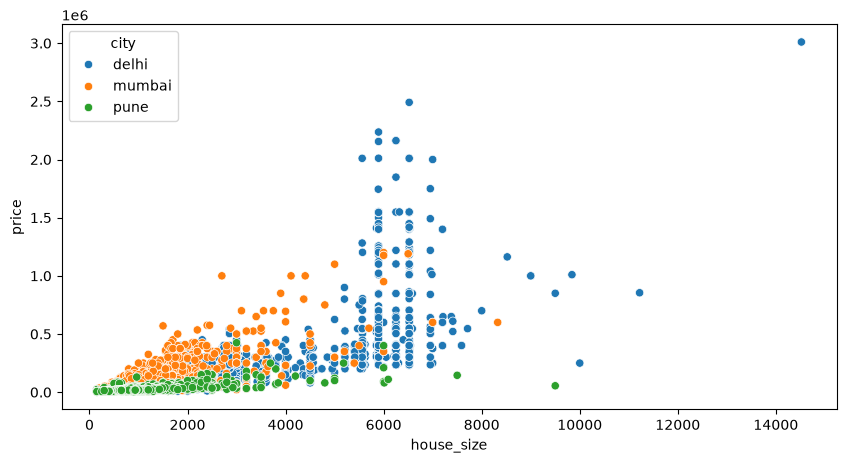

In [16]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="house_size", y="price", hue="city")
plt.show()

#### We can see that the majority of properties in the dataset have a house size between 500 and 2000 sqft. This suggests that most buyers are looking for properties within this size range, which could be due to factors such as affordability, lifestyle preferences, or the availability of housing stock in the area.

#### Also as the house size increases, the price of the property also increases. This indicates a positive correlation between house size and price, which is expected as larger properties typically command higher prices in the real estate market.

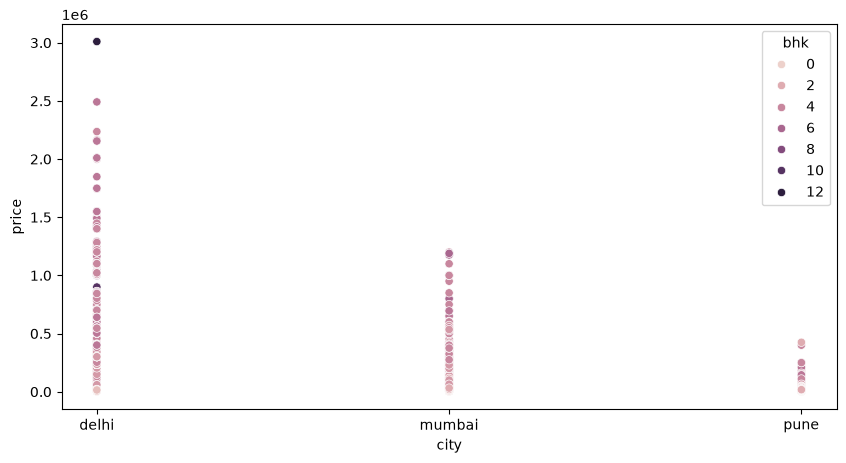

In [17]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="city", y="price", hue="bhk")
plt.show()

##### We can see that the city delhi has the highest number of house properties in the dataset.
##### there are a few properties in delhi with price greater than 1M, which indicates that there are some high-end properties in the city. However, the majority of properties in delhi have prices below 1M, which suggests that there is a wide range of housing options available in the city, catering to different budget levels.

In [18]:
df['latitude']

0        28.545561
1        28.643259
2        28.618677
3        28.712898
4        28.723539
           ...    
13905    18.603699
13906    18.594870
13907    18.595701
13908    18.592476
13909    18.600847
Name: latitude, Length: 13902, dtype: float64

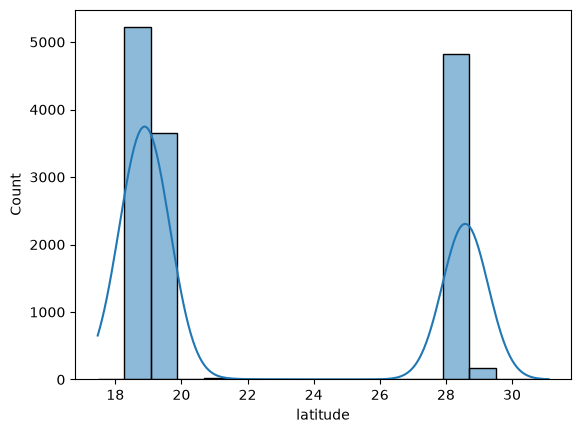

In [19]:
sns.histplot(data=df, x="latitude", kde=True)
plt.show()

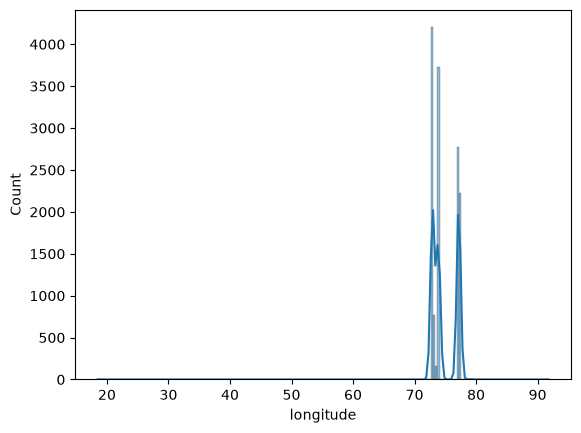

In [20]:
sns.histplot(data=df, x="longitude", kde=True)
plt.show()

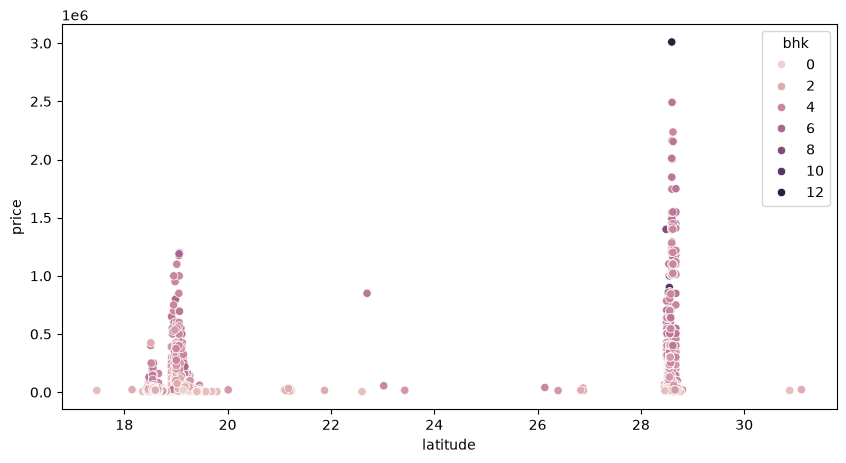

In [21]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="latitude", y="price", hue="bhk")
plt.show()

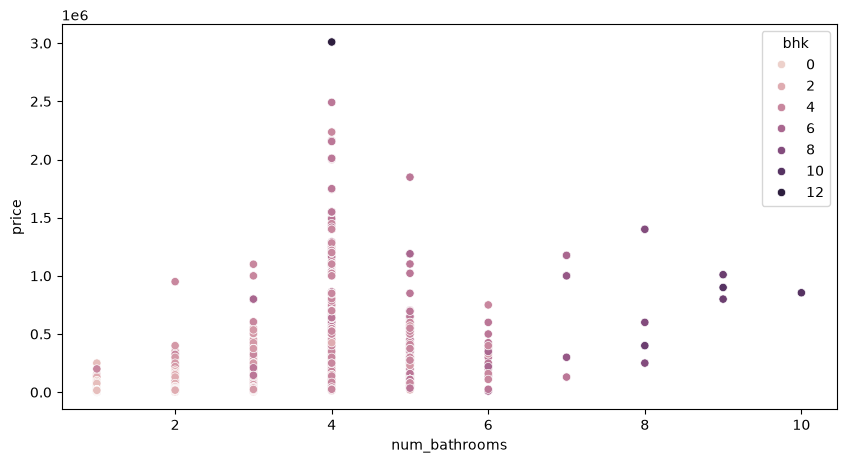

In [22]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="num_bathrooms", y="price", hue="bhk")
plt.show()

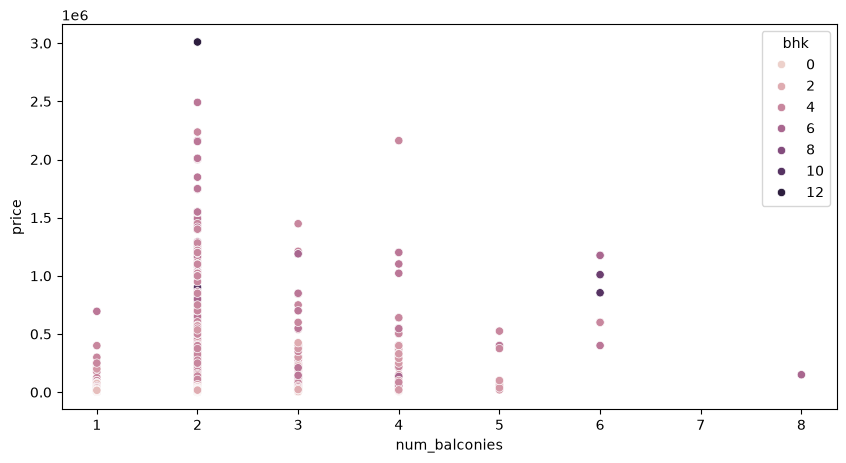

In [23]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="num_balconies", y="price", hue="bhk")
plt.show()

In [24]:
df.columns

Index(['house_type', 'house_size', 'location', 'city', 'latitude', 'longitude',
       'price', 'num_bathrooms', 'num_balconies', 'is_negotiable',
       'price_sqft', 'verification_date', 'description', 'security_deposite',
       'Status', 'source_file', 'bhk', 'property_type', 'verification_days'],
      dtype='str')

In [25]:
df.groupby(['house_type', 'house_size'])['price'].mean()

house_type                house_size
1 BHK Apartment           150              4000.0
                          200              7000.0
                          250             11750.0
                          270              6000.0
                          275             18500.0
                                          ...    
8 BHK Independent House   7200           600000.0
8 BHK Villa               10000          250000.0
9 BHK Independent House   3510           400000.0
                          5200           800000.0
                          9841          1010102.0
Name: price, Length: 1816, dtype: float64

<Axes: xlabel='house_type,house_size'>

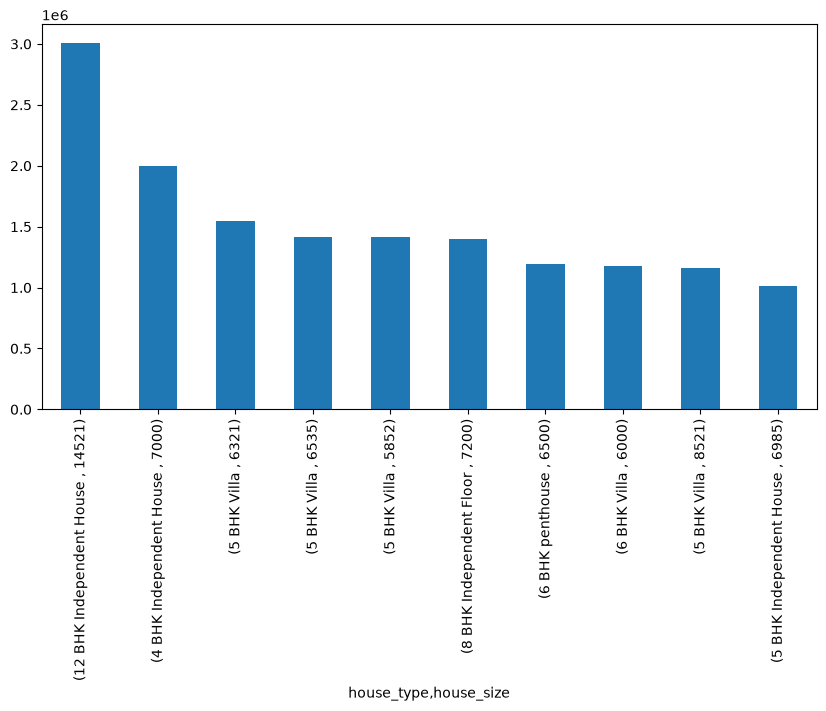

In [42]:
plt.figure(figsize=(10, 5))
df.groupby(['house_type', 'house_size'])['price'].mean().nlargest(10).plot(kind='bar')


<Axes: xlabel='house_type,city'>

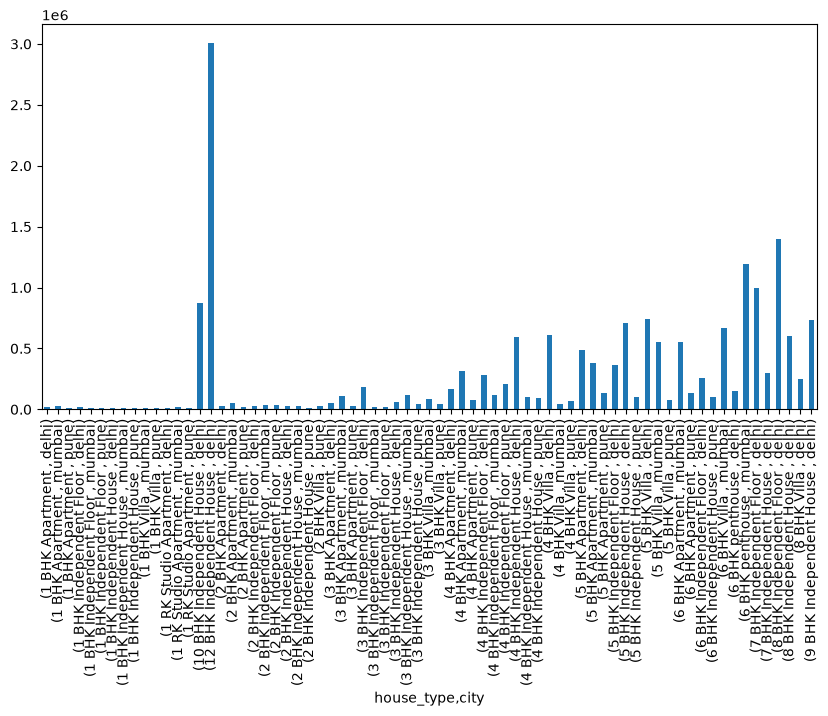

In [44]:
plt.figure(figsize=(10, 5))
df.groupby(['house_type', 'city'])['price'].mean().plot(kind='bar')

In [46]:
df.groupby(['city'])['price_sqft'].mean()

city
delhi    NaN
mumbai   NaN
pune     NaN
Name: price_sqft, dtype: float64

In [47]:
df['price_sqft']

0       NaN
1       NaN
2       NaN
3       NaN
4       NaN
         ..
13905   NaN
13906   NaN
13907   NaN
13908   NaN
13909   NaN
Name: price_sqft, Length: 13902, dtype: float64

In [48]:
df.isnull().sum()

house_type               0
house_size               0
location                 0
city                     0
latitude                 0
longitude                0
price                    0
num_bathrooms            0
num_balconies            0
is_negotiable            0
price_sqft           13902
verification_date        0
description            831
security_deposite    13902
Status                   0
source_file              0
bhk                      0
property_type          542
verification_days     4140
dtype: int64

In [54]:
df.groupby(['location', 'city'])['price'].mean().sort_index(ascending=True).reset_index()

,location,city,price
0,aarya chanakya nagar,mumbai,18000.000000
1,abul fazal enclave jamia nagar,delhi,14833.333333
2,agalambe,pune,6500.000000
3,agcr enclave,delhi,42000.000000
4,agripada,mumbai,317500.000000
...,...,...,...
694,yerawada,pune,23871.428571
695,yewalewadi,pune,8500.000000
696,yogi nagar,mumbai,25000.000000
697,yojna vihar,delhi,19000.000000


<Axes: >

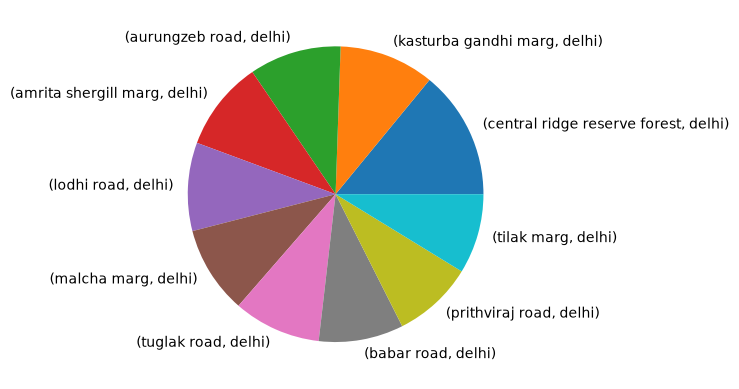

In [59]:
df.groupby(['location', 'city'])['price'].mean().sort_index(ascending=True).nlargest(10).plot(kind='pie')

In [61]:
df['verification_date'].value_counts()

verification_date
Posted 3 years ago       2387
Posted a year ago        2315
Posted a month ago       1714
Posted 2 months ago      1191
Posted 5 months ago       865
                         ... 
Posted 20 hours ago         1
Posted 18 hours ago         1
Posted 33 minutes ago       1
Posted 3 hours ago          1
Posted 7 months ago         1
Name: count, Length: 62, dtype: int64

In [64]:
df.groupby(['verification_date', 'verification_days'])['price'].mean()

verification_date      verification_days
Posted 10 days ago     10.0                  79224.150327
Posted 10 hours ago    10.0                  43193.548387
Posted 10 months ago   10.0                  49285.714286
Posted 11 days ago     11.0                  42622.971831
Posted 11 hours ago    11.0                  42625.000000
Posted 12 days ago     12.0                  66045.775701
Posted 13 days ago     13.0                  41410.476190
Posted 13 hours ago    13.0                  35236.842105
Posted 14 days ago     14.0                  26329.463158
Posted 14 hours ago    14.0                  27733.333333
Posted 15 days ago     15.0                  76909.296512
Posted 15 hours ago    15.0                  22000.000000
Posted 16 days ago     16.0                 152202.292264
Posted 16 hours ago    16.0                  34750.000000
Posted 17 days ago     17.0                  37605.714286
Posted 17 hours ago    17.0                  72181.636364
Posted 18 days ago     18.0    

In [63]:
df['verification_days']

0         NaN
1         9.0
2        12.0
3         NaN
4         NaN
         ... 
13905     3.0
13906     3.0
13907     3.0
13908     3.0
13909     3.0
Name: verification_days, Length: 13902, dtype: float64

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data: 'DataParamType' = None, **kwargs) -> 'list[Line2D]'>

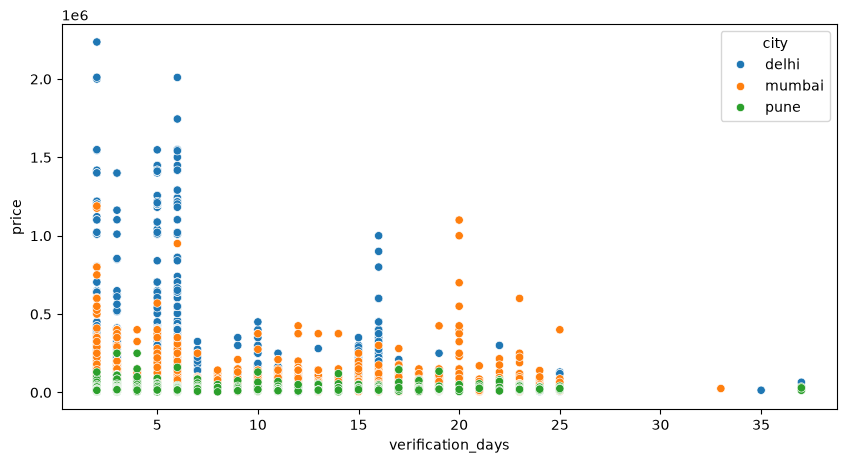

In [65]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="verification_days", y='price', hue='city')
plt.plot

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data: 'DataParamType' = None, **kwargs) -> 'list[Line2D]'>

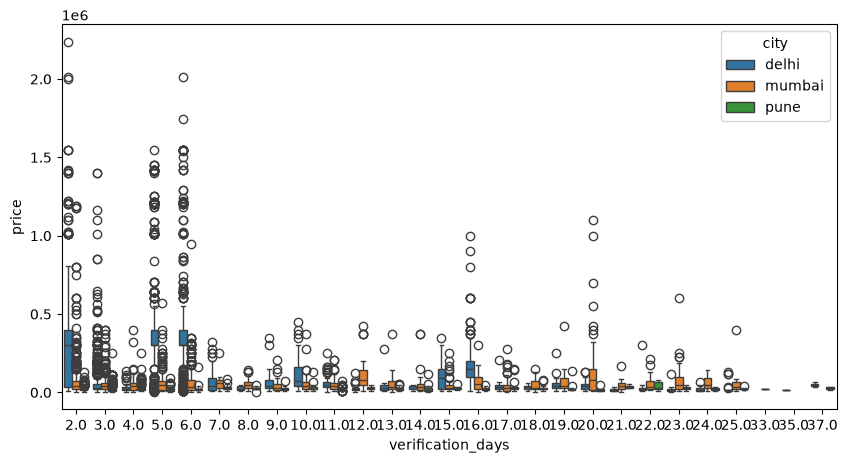

In [66]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="verification_days", y='price', hue='city')
plt.plot

In [68]:
df['security_deposite'].value_counts()

Series([], Name: count, dtype: int64)

In [69]:
df['Status'].value_counts()

Status
Unfurnished       5612
Semi-Furnished    5546
Furnished         2744
Name: count, dtype: int64

<Axes: >

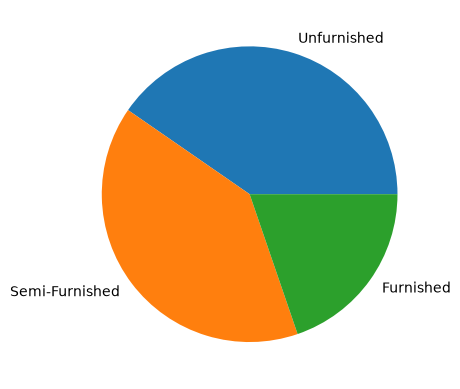

In [71]:
df['Status'].value_counts().plot(kind='pie')

<function matplotlib.pyplot.plot(*args: 'float | ArrayLike | str', scalex: 'bool' = True, scaley: 'bool' = True, data: 'DataParamType' = None, **kwargs) -> 'list[Line2D]'>

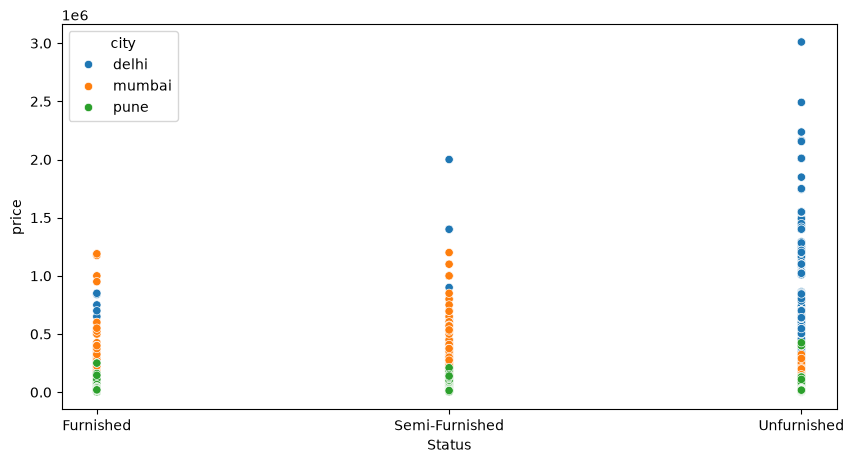

In [73]:
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df, x="Status", y='price', hue='city')
plt.plot

In [75]:
num_cols

Index(['house_size', 'latitude', 'longitude', 'price', 'num_bathrooms',
       'num_balconies', 'is_negotiable', 'price_sqft', 'security_deposite',
       'bhk', 'verification_days'],
      dtype='str')

In [76]:
df[num_cols]

,house_size,latitude,longitude,price,num_bathrooms,num_balconies,is_negotiable,price_sqft,security_deposite,bhk,verification_days
0,400,28.545561,77.254349,22000,1,2,0,NaN,NaN,0,NaN
1,400,28.643259,77.132828,20000,1,2,0,NaN,NaN,0,9.0
2,500,28.618677,77.053352,8500,1,2,0,NaN,NaN,2,12.0
3,1020,28.712898,77.180000,48000,3,2,0,NaN,NaN,3,NaN
4,810,28.723539,77.131424,20000,2,2,0,NaN,NaN,2,NaN
...,...,...,...,...,...,...,...,...,...,...,...
13905,655,18.603699,73.761238,12500,1,2,0,NaN,NaN,1,3.0
13906,920,18.594870,73.798187,16000,2,2,0,NaN,NaN,2,3.0
13907,650,18.595701,73.797890,16000,1,1,0,NaN,NaN,1,3.0
13908,1200,18.592476,73.798538,20000,2,2,0,NaN,NaN,2,3.0


In [78]:
corr = df[num_cols].corr()

In [79]:
corr

,house_size,latitude,longitude,price,num_bathrooms,num_balconies,is_negotiable,price_sqft,security_deposite,bhk,verification_days
house_size,1.000000,0.559533,0.484275,0.783961,0.800150,0.193360,NaN,NaN,NaN,0.823483,-0.057810
latitude,0.559533,1.000000,0.841969,0.440189,0.438283,0.069108,NaN,NaN,NaN,0.486508,0.085160
longitude,0.484275,0.841969,1.000000,0.359804,0.376493,0.019615,NaN,NaN,NaN,0.427276,0.057698
price,0.783961,0.440189,0.359804,1.000000,0.619516,0.153888,NaN,NaN,NaN,0.630695,-0.055792
num_bathrooms,0.800150,0.438283,0.376493,0.619516,1.000000,0.243736,NaN,NaN,NaN,0.900381,-0.005912
num_balconies,0.193360,0.069108,0.019615,0.153888,0.243736,1.000000,NaN,NaN,NaN,0.208843,0.064543
is_negotiable,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price_sqft,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
security_deposite,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
bhk,0.823483,0.486508,0.427276,0.630695,0.900381,0.208843,NaN,NaN,NaN,1.000000,-0.009864


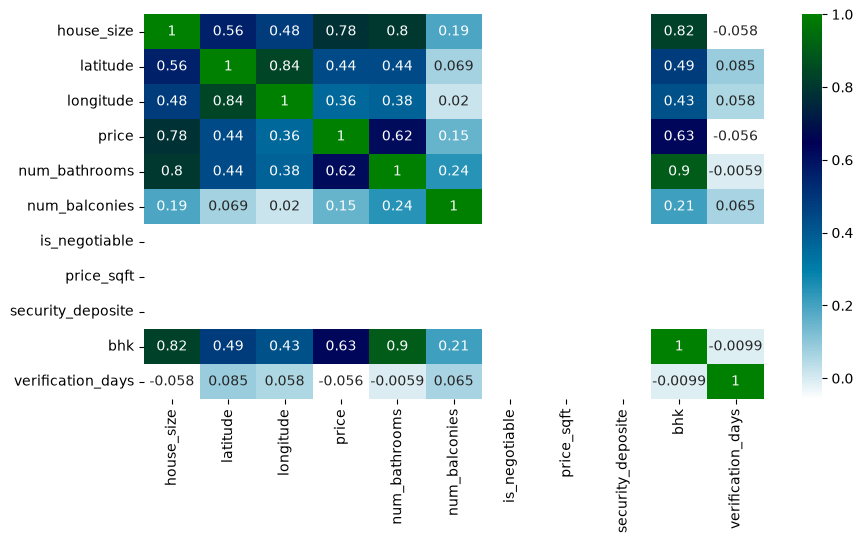

In [83]:
plt.figure(figsize=(10, 5))
sns.heatmap(data=corr, annot=True, cmap="ocean_r")
plt.show()

In [102]:
data_points = [1, 2, 3, 4, 5, 100]

In [103]:
total = 0
for i in data_points:
    total += i

avg = total/len(data_points)
print(avg)

19.166666666666668


<Axes: ylabel='Count'>

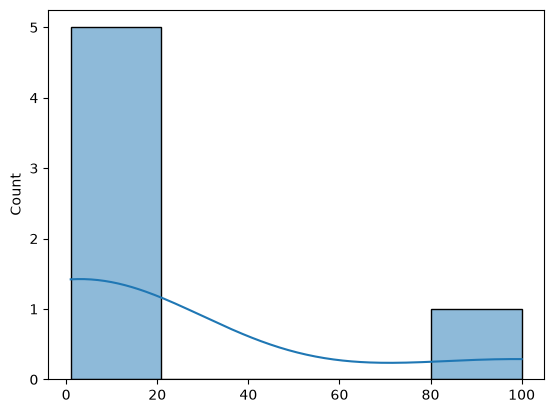

In [104]:
sns.histplot(data_points, kde=True)

<Axes: >

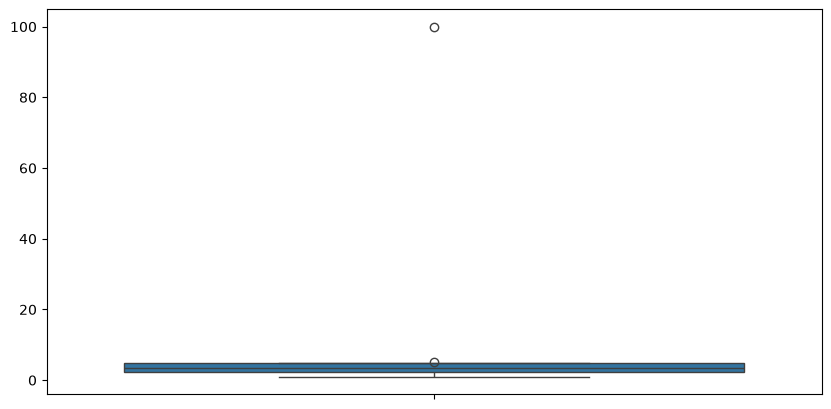

In [111]:
plt.figure(figsize=(10, 5))
sns.boxplot(data_points, whis=(0, 50))

In [112]:
import plotly.express as px

In [ ]:
# px.box(data_points)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'alignmentgroup': 'True',
              'hovertemplate': 'variable=%{x}<br>value=%{y}<extra></extra>',
              'legendgroup': '',
              'marker': {'color': '#636efa'},
              'name': '',
              'notched': False,
              'offsetgroup': '',
              'orientation': 'v',
              'showlegend': False,
              'type': 'box',
              'x': array(['0', '0', '0', '0', '0', '0'], dtype=object),
              'x0': ' ',
              'xaxis': 'x',
              'y': {'bdata': 'AQIDBAVk', 'dtype': 'i1'},
              'y0': ' ',
              'yaxis': 'y'}],
    'layout': {'boxmode': 'group',
               'legend': {'tracegroupgap': 0},
               'margin': {'t': 60},
               'template': '...',
               'xaxis': {'anchor': 'y', 'domain': [0.0, 1.0], 'title': {'text': 'variable'}},
               'yaxis': {'anchor': 'x', 'domain': [0.0, 1.0], 'title': {'text': 'value'}}}
})